<a href="https://colab.research.google.com/github/patrickmurayari/tpi-ia-patologias-tomate/blob/main/notebooks/01_eda_y_particion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import random
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Semilla global para garantizar reproducibilidad estricta
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Definición de directorios base
BASE_DIR = Path("/content/plantvillage_tomate")
RAW_DIR = BASE_DIR / "raw"
SPLITS_DIR = BASE_DIR / "splits"

RAW_DIR.mkdir(parents=True, exist_ok=True)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Entorno configurado. Directorio de trabajo: {BASE_DIR}")

Entorno configurado. Directorio de trabajo: /content/plantvillage_tomate


In [2]:
%%bash
cd /content/plantvillage_tomate/raw
if [ ! -d "PlantVillage-Dataset" ]; then
    git clone --filter=blob:none --no-checkout --depth 1 https://github.com/spmohanty/PlantVillage-Dataset.git
    cd PlantVillage-Dataset
    git sparse-checkout init --cone
    git sparse-checkout set "raw/color/Tomato___Bacterial_spot" \
                            "raw/color/Tomato___Early_blight" \
                            "raw/color/Tomato___Late_blight" \
                            "raw/color/Tomato___Leaf_Mold" \
                            "raw/color/Tomato___Septoria_leaf_spot" \
                            "raw/color/Tomato___Spider_mites Two-spotted_spider_mite" \
                            "raw/color/Tomato___Target_Spot" \
                            "raw/color/Tomato___Tomato_Yellow_Leaf_Curl_Virus" \
                            "raw/color/Tomato___Tomato_mosaic_virus" \
                            "raw/color/Tomato___healthy"
    git checkout
else
    echo "El repositorio ya fue descargado."
fi

Your branch is up to date with 'origin/master'.


Cloning into 'PlantVillage-Dataset'...


In [3]:
DATASET_ROOT = RAW_DIR / "PlantVillage-Dataset" / "raw" / "color"

records = []
valid_extensions = {".jpg", ".jpeg", ".png"}

for class_dir in sorted(DATASET_ROOT.iterdir()):
    if not class_dir.is_dir() or not class_dir.name.startswith("Tomato___"):
        continue

    # Limpiamos el prefijo para legibilidad en gráficos y tablas
    clean_label = class_dir.name.replace("Tomato___", "")

    for img_path in sorted(class_dir.iterdir()):
        if img_path.suffix.lower() not in valid_extensions:
            continue

        try:
            # Verificación de lectura y metadatos básicos
            with Image.open(img_path) as img:
                width, height = img.size
                mode = img.mode

            # Cálculo de hash MD5 para detectar duplicados exactos
            file_hash = hashlib.md5(img_path.read_bytes()).hexdigest()

            records.append({
                "filepath": str(img_path),
                "filename": img_path.name,
                "label": clean_label,
                "width": width,
                "height": height,
                "mode": mode,
                "md5": file_hash
            })
        except Exception as e:
            print(f"Archivo corrupto ignorado: {img_path} -> {e}")

df_all = pd.DataFrame(records)
print(f"Total de imágenes indexadas: {len(df_all)}")
print(f"Clases detectadas: {df_all['label'].nunique()}")

# Eliminación de duplicados exactos por MD5
duplicados = df_all.duplicated(subset=["md5"]).sum()
print(f"Duplicados exactos encontrados: {duplicados}")

df_clean = df_all.drop_duplicates(subset=["md5"]).reset_index(drop=True)
print(f"Total tras deduplicación: {len(df_clean)}")

Total de imágenes indexadas: 18160
Clases detectadas: 10
Duplicados exactos encontrados: 14
Total tras deduplicación: 18146


,Patologia,Cantidad,Porcentaje (%)
0,Tomato_Yellow_Leaf_Curl_Virus,5357,29.52
1,Bacterial_spot,2127,11.72
2,Late_blight,1901,10.48
3,Septoria_leaf_spot,1771,9.76
4,Spider_mites Two-spotted_spider_mite,1676,9.24
5,healthy,1585,8.73
6,Target_Spot,1404,7.74
7,Early_blight,1000,5.51
8,Leaf_Mold,952,5.25
9,Tomato_mosaic_virus,373,2.06



Resoluciones únicas: [{'width': 256, 'height': 256}]
Modos de color únicos: ['RGB']


/tmp/ipykernel_896/637750571.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=class_counts, x="Cantidad", y="Patologia", palette="viridis")


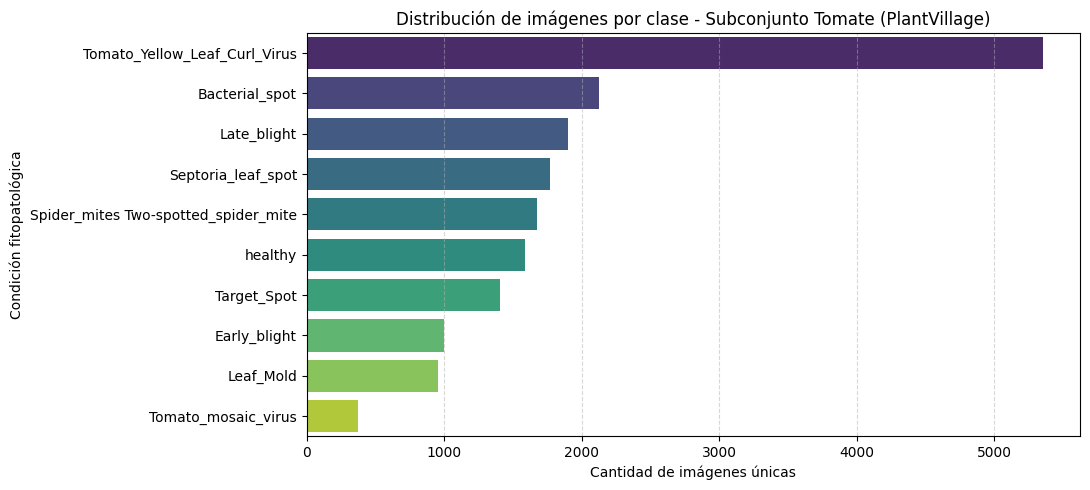

In [4]:
# Resumen estadístico por clase
class_counts = df_clean["label"].value_counts().reset_index()
class_counts.columns = ["Patologia", "Cantidad"]
class_counts["Porcentaje (%)"] = (class_counts["Cantidad"] / len(df_clean) * 100).round(2)
display(class_counts)

# Verificación de homogeneidad de dimensiones y canales
print("\nResoluciones únicas:", df_clean[["width", "height"]].drop_duplicates().to_dict("records"))
print("Modos de color únicos:", df_clean["mode"].unique())

# Visualización de distribución de clases
plt.figure(figsize=(11, 5))
sns.barplot(data=class_counts, x="Cantidad", y="Patologia", palette="viridis")
plt.title("Distribución de imágenes por clase - Subconjunto Tomate (PlantVillage)")
plt.xlabel("Cantidad de imágenes únicas")
plt.ylabel("Condición fitopatológica")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(SPLITS_DIR / "distribucion_clases.png", dpi=300)
plt.show()

In [5]:
# Mapeo numérico ordenado alfabéticamente
label_names = sorted(df_clean["label"].unique())
label_to_idx = {name: idx for idx, name in enumerate(label_names)}
df_clean["label_idx"] = df_clean["label"].map(label_to_idx)

# Primera división: 70% Train, 30% Temporal (Val + Test)
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.30,
    stratify=df_clean["label_idx"],
    random_state=SEED
)

# Segunda división: el 30% temporal se parte a la mitad (15% Val, 15% Test)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_idx"],
    random_state=SEED
)

train_df = train_df.assign(split="train")
val_df = val_df.assign(split="val")
test_df = test_df.assign(split="test")

df_splits = pd.concat([train_df, val_df, test_df], ignore_index=True)

# Guardamos el manifiesto con rutas relativas para portabilidad en GitHub
df_splits["rel_path"] = df_splits["filepath"].apply(
    lambda p: str(Path(p).relative_to(RAW_DIR / "PlantVillage-Dataset"))
)

manifest_path = SPLITS_DIR / "tomate_splits_seed42.csv"
df_splits[["rel_path", "filename", "label", "label_idx", "split"]].to_csv(manifest_path, index=False)

print("Partición completada y guardada en:", manifest_path)
print(pd.crosstab(df_splits["label"], df_splits["split"], margins=True))

Partición completada y guardada en: /content/plantvillage_tomate/splits/tomate_splits_seed42.csv
split                                 test  train   val    All
label                                                         
Bacterial_spot                         319   1489   319   2127
Early_blight                           150    700   150   1000
Late_blight                            285   1331   285   1901
Leaf_Mold                              143    666   143    952
Septoria_leaf_spot                     266   1240   265   1771
Spider_mites Two-spotted_spider_mite   251   1173   252   1676
Target_Spot                            211    983   210   1404
Tomato_Yellow_Leaf_Curl_Virus          803   3750   804   5357
Tomato_mosaic_virus                     56    261    56    373
healthy                                238   1109   238   1585
All                                   2722  12702  2722  18146


In [6]:
from google.colab import files

# Descarga directa a tu computadora local sin pasar por Drive
files.download("/content/plantvillage_tomate/splits/tomate_splits_seed42.csv")
files.download("/content/plantvillage_tomate/splits/distribucion_clases.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>